In [ ]:
import os, glob, time, warnings          # os/glob: file paths, time: timing, warnings: silence sklearn noise
warnings.filterwarnings("ignore")        # hides harmless version-mismatch warnings from sklearn/pandas

import numpy as np                       # numerical arrays
import pandas as pd                      # dataframes — main tool for loading/reshaping the data

# ---------------- CONFIG ----------------
DATA_DIR    = "/content/physionet2019"   # where we'll extract the .psv files to
CACHE_DIR   = "/content/cache"           # where we save the processed data so we don't redo work
N_PATIENTS  = 5000                       # limit patients while testing; set to None for the full run
RANDOM_SEED = 42                         # fixed seed -> same random split/results every run (reproducibility)
ROLL_WINDOW = 6                          # hours of history used for rolling average/min/max features
TEST_FRAC   = 0.15                       # 15% of patients held out for final testing
VAL_FRAC    = 0.15                       # 15% of patients held out for tuning (threshold, model choice)
# ----------------------------------------

os.makedirs(DATA_DIR, exist_ok=True)     # create the folder if it doesn't already exist
os.makedirs(CACHE_DIR, exist_ok=True)    # same for the cache folder
np.random.seed(RANDOM_SEED)              # seed numpy's random generator globally too

import matplotlib.pyplot as plt          # for plots
import seaborn as sns                    # nicer-looking statistical plots, built on matplotlib
from sklearn.model_selection import train_test_split          # splits data into train/val/test
from sklearn.impute import SimpleImputer                       # fills missing values (median/mean)
from sklearn.preprocessing import StandardScaler                # rescales features to mean 0, std 1
from sklearn.linear_model import LogisticRegression             # model 1: Logistic Regression
from sklearn.svm import LinearSVC, SVC                          # model 2: SVM (linear + kernel versions)
from sklearn.ensemble import RandomForestClassifier              # model 3: Random Forest
from sklearn.tree import DecisionTreeClassifier                  # model 4: Decision Tree
from sklearn.metrics import (                                    # all the scoring functions we'll need
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve)

plt.rcParams["figure.dpi"] = 110         # slightly sharper plots
sns.set_style("whitegrid")               # light grid background for all seaborn plots
print("setup complete")                  # confirms this cell ran without errors

setup complete


In [ ]:
from google.colab import files           # Colab's built-in browser file-upload helper
print("choose your zip file (archive__8_.zip) in the dialog that appears...")

uploaded = files.upload()                # opens a file picker in your browser — select the zip and it uploads

zip_name = list(uploaded.keys())[0]      # gets the filename you just uploaded (e.g. "archive__8_.zip")
DRIVE_ZIP = f"/content/{zip_name}"       # local path in the Colab VM where the file was saved

print(f"uploaded: {zip_name} ({len(uploaded[zip_name])/1e6:.0f} MB)")   # confirm size to check nothing got cut off

choose your zip file (archive__8_.zip) in the dialog that appears...


Saving archive (8).zip to archive (8).zip
uploaded: archive (8).zip (47 MB)


In [ ]:
%%time
# -q = quiet (no per-file spam)   -o = overwrite if re-run   -d = destination folder
!unzip -q -o "{DRIVE_ZIP}" -d {DATA_DIR}

# recursive=True lets glob search inside nested subfolders (your zip has training_setA/training_setA/...)
files_all = sorted(glob.glob(f"{DATA_DIR}/**/*.psv", recursive=True))

# fail loudly and immediately if something went wrong, instead of a confusing error later
if not files_all:
    raise FileNotFoundError(f"No .psv files found under {DATA_DIR} — check the unzip output above.")

print(len(files_all), "psv files found")     # should print 40336
print("example path:", files_all[0])         # sanity check the path structure looks right

40336 psv files found
example path: /content/physionet2019/training_setA/training_setA/p000001.psv
CPU times: user 98.4 ms, sys: 22.8 ms, total: 121 ms
Wall time: 3.93 s


In [ ]:
%%time
# -q = quiet (no per-file spam)   -o = overwrite if re-run   -d = destination folder
!unzip -q -o "{DRIVE_ZIP}" -d {DATA_DIR}

# recursive=True lets glob search inside nested subfolders (your zip has training_setA/training_setA/...)
files_all = sorted(glob.glob(f"{DATA_DIR}/**/*.psv", recursive=True))

# fail loudly and immediately if something went wrong, instead of a confusing error later
if not files_all:
    raise FileNotFoundError(f"No .psv files found under {DATA_DIR} — check the unzip output above.")

print(len(files_all), "psv files found")     # should print 40336
print("example path:", files_all[0])         # sanity check the path structure looks right

40336 psv files found
example path: /content/physionet2019/training_setA/training_setA/p000001.psv
CPU times: user 84.4 ms, sys: 30.6 ms, total: 115 ms
Wall time: 7.83 s


In [ ]:
%%time
RAW_CACHE = f"{CACHE_DIR}/raw.parquet"       # path where we'll save the combined result

if os.path.exists(RAW_CACHE):                 # if we already built this once, just reload it (fast)
    raw = pd.read_parquet(RAW_CACHE)
    print("loaded from cache")
else:                                         # otherwise build it from scratch (slow, ~10-20 min for all files)
    files = files_all                         # use every file found above
    if N_PATIENTS:                            # if we're in "testing mode" with a patient limit...
        rs = np.random.RandomState(RANDOM_SEED)                       # separate seeded RNG for reproducible sampling
        files = list(rs.choice(files, size=min(N_PATIENTS, len(files)), replace=False))  # pick a random subset
    print(len(files), "files to read")

    frames, t0 = [], time.time()              # frames = list to collect each patient's table; t0 = start time
    for i, f in enumerate(files):             # loop over every file path
        d = pd.read_csv(f, sep="|")           # read one patient's file — pipe-separated, not comma
        pid = os.path.basename(f).split(".")[0]        # extract "p000001" from the full file path
        d["patient"]  = pid                   # tag every row of this file with its patient ID
        d["hospital"] = "A" if pid[1] == "0" else "B"   # p0xxxxx = Hospital A, p1xxxxx = Hospital B
        frames.append(d)                      # add this patient's table to our collection
        if (i+1) % 5000 == 0:                 # every 5000 files, print a progress update
            print(f"  {i+1}/{len(files)}  {time.time()-t0:.0f}s elapsed")

    raw = pd.concat(frames, ignore_index=True)   # stack all patient tables into one big dataframe
    del frames                                    # free the memory used by the list of small dataframes

    # downcast float64 -> float32: halves memory use, no meaningful precision loss for this data
    for c in raw.select_dtypes("float64").columns:
        raw[c] = raw[c].astype("float32")
    raw["SepsisLabel"] = raw["SepsisLabel"].astype("int8")     # label is just 0/1, tiny integer type is enough
    raw["patient"]  = raw["patient"].astype("category")        # category dtype is much smaller than plain string
    raw["hospital"] = raw["hospital"].astype("category")
    raw.to_parquet(RAW_CACHE, index=False)      # save to disk so we NEVER have to redo this 10-20 min step again

print(raw.shape, "| unique patients:", raw["patient"].nunique())
raw.head()                                        # show the first few rows to eyeball the data

5000 files to read
  5000/5000  12s elapsed
(191583, 43) | unique patients: 5000
CPU times: user 14.1 s, sys: 403 ms, total: 14.5 s
Wall time: 14.7 s


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient,hospital
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,76.0,1,NaN,NaN,-49.080002,1,0,p101214,B
1,98.0,98.0,NaN,121.0,82.0,64.0,24.0,NaN,NaN,NaN,...,NaN,76.0,1,NaN,NaN,-49.080002,2,0,p101214,B
2,103.0,96.0,NaN,116.0,84.0,59.0,28.0,NaN,NaN,NaN,...,NaN,76.0,1,NaN,NaN,-49.080002,3,0,p101214,B
3,108.0,98.0,NaN,150.0,101.0,73.0,24.0,NaN,NaN,NaN,...,NaN,76.0,1,NaN,NaN,-49.080002,4,0,p101214,B
4,109.0,98.0,36.799999,120.0,78.0,62.0,24.0,NaN,NaN,NaN,...,NaN,76.0,1,NaN,NaN,-49.080002,5,0,p101214,B


In [ ]:
pat_lvl = raw.groupby("patient", observed=True)["SepsisLabel"].max()   # per patient: did they ever get sepsis? (1/0)
pos_rate = raw["SepsisLabel"].mean()                                    # fraction of ALL rows that are sepsis=1

print(f"Total patient-hours   : {len(raw):,}")                          # total rows = total hours across all patients
print(f"Total patients        : {len(pat_lvl):,}")
print(f"Septic patients       : {pat_lvl.sum():,} ({100*pat_lvl.mean():.2f}%)")   # how many patients ever went septic
print(f"Positive hours        : {raw['SepsisLabel'].sum():,} ({100*pos_rate:.2f}%)")  # how many individual hours are labelled sepsis
print(f"Imbalance ratio       : 1 : {int((1-pos_rate)/pos_rate)}")       # e.g. "1:54" -- for every sepsis hour, 54 normal hours
print(f"Median ICU stay (h)   : {raw.groupby('patient', observed=True).size().median():.0f}")  # typical stay length

Total patient-hours   : 191,583
Total patients        : 5,000
Septic patients       : 325 (6.50%)
Positive hours        : 3,068 (1.60%)
Imbalance ratio       : 1 : 61
Median ICU stay (h)   : 39


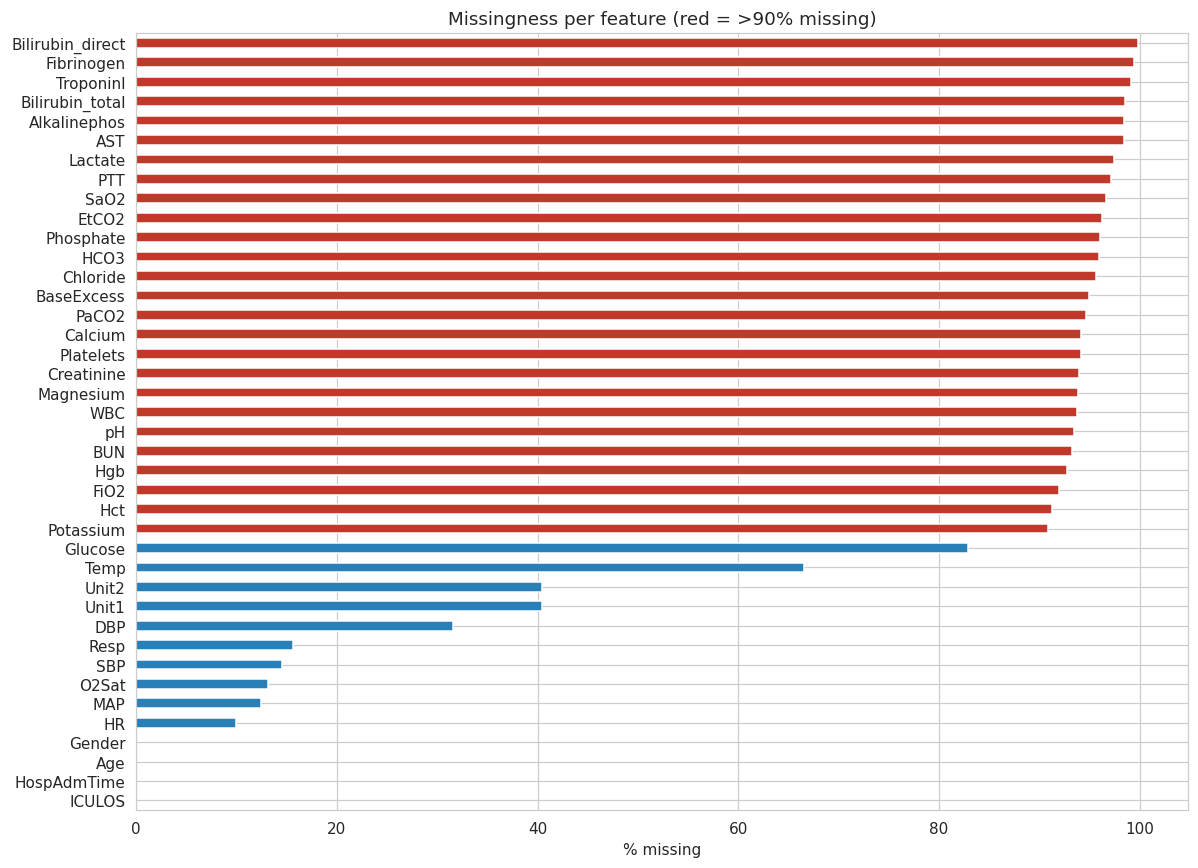

Features >90% missing: 26 of 40


In [ ]:
# how much data is missing per column — this dataset's defining challenge
miss = raw.drop(columns=["patient","hospital","SepsisLabel"]).isna().mean().sort_values() * 100  # % missing per column
fig, ax = plt.subplots(figsize=(11,8))                                    # create a figure to draw on
miss.plot.barh(ax=ax, color=np.where(miss > 90, "#c0392b", "#2980b9"))    # red bars if >90% missing, else blue
ax.set_xlabel("% missing")
ax.set_title("Missingness per feature (red = >90% missing)")
plt.tight_layout(); plt.show()                                             # render the plot
print("Features >90% missing:", (miss > 90).sum(), "of", len(miss))       # count of very sparse columns

In [ ]:
# column groups, matching the dataset's documented schema
VITALS = ['HR','O2Sat','Temp','SBP','MAP','DBP','Resp','EtCO2']           # vital signs — measured often
LABS   = ['BaseExcess','HCO3','FiO2','pH','PaCO2','SaO2','AST','BUN','Alkalinephos','Calcium',
          'Chloride','Creatinine','Bilirubin_direct','Glucose','Lactate','Magnesium','Phosphate',
          'Potassium','Bilirubin_total','TroponinI','Hct','Hgb','PTT','WBC','Fibrinogen','Platelets']  # lab tests — sparse
STATIC = ['Age','Gender','Unit1','Unit2','HospAdmTime','ICULOS']          # patient-level / time-index columns

# the subset of signals dense/important enough to justify computing rolling trend features for
KEY = ['HR','MAP','Resp','Temp','O2Sat','SBP','Lactate','WBC','Creatinine','BUN',
       'Platelets','Hct','Glucose','pH']

def build_features(df, roll=ROLL_WINDOW):
    df  = df.sort_values(["patient","ICULOS"]).reset_index(drop=True)   # sort so each patient's hours are in order
    pid = df["patient"]                                                  # shortcut reference to the patient-id column
    parts = [df[STATIC].astype("float32")]                               # start our feature list with the static columns

    # --- (a) missingness indicators: WAS this lab measured at this hour? (before we fill anything) ---
    m = df[LABS].isna().astype("int8")            # 1 if missing, 0 if present, for every lab column
    m.columns = [c+"_msg" for c in LABS]           # rename columns e.g. "Lactate" -> "Lactate_msg"
    parts.append(m)                                # add to our growing feature set

    # --- (b) cumulative count: HOW MANY TIMES has this signal been measured so far for this patient? ---
    cnt = df[KEY].notna().astype("int16").groupby(pid, observed=True).cumsum()   # running total, resets per patient
    cnt.columns = [c+"_cnt" for c in KEY]
    parts.append(cnt.astype("int16"))

    # --- (c) forward-fill: carry the last known value forward in time, WITHIN each patient only ---
    filled = df[VITALS+LABS].groupby(pid, observed=True).ffill().astype("float32")  # groupby ensures no bleed across patients
    parts.append(filled)

    # --- (d) rolling statistics over the last `roll` hours: captures TRENDS, not just single readings ---
    g = filled[KEY].groupby(pid, observed=True, sort=False)   # group the key signals by patient
    r = g.rolling(roll, min_periods=1)                         # rolling window object, min_periods=1 avoids NaN at the start
    for name in ["mean","min","max","std"]:                    # compute 4 different rolling summaries
        out = getattr(r, name)().reset_index(level=0, drop=True).sort_index()  # e.g. r.mean(), r.min(), etc.
        out.columns = [f"{c}_{name}{roll}" for c in KEY]        # rename e.g. "HR_mean6"
        parts.append(out.astype("float32"))

    # --- (e) hour-to-hour change, and drift from this patient's own baseline (first reading) ---
    d1 = g.diff()                                    # difference from the previous hour (rate of change)
    d1.columns = [c+"_d1" for c in KEY]
    parts.append(d1.astype("float32"))
    base  = g.transform("first")                      # this patient's very first recorded value for each signal
    delta = pd.DataFrame((filled[KEY].values - base.values).astype("float32"),  # how far we've drifted from admission
                         columns=[c+"_dbase" for c in KEY], index=filled.index)
    parts.append(delta)

    X = pd.concat(parts, axis=1)                       # glue all feature groups together into one wide table
    X.columns = [str(c) for c in X.columns]             # ensure all column names are plain strings
    # return: X = features, y = labels, meta = bookkeeping columns we'll need later (patient id, hour, hospital)
    return X, df["SepsisLabel"].astype("int8").values, df[["patient","hospital","ICULOS","SepsisLabel"]]

In [ ]:
%%time
X, y, meta = build_features(raw)                        # run the function above on our full dataset
print("feature matrix:", X.shape)                        # should be ~164 columns, expanded from the original 40
print("memory: {:.2f} GB".format(X.memory_usage(deep=True).sum()/1e9))   # how much RAM the feature table uses

feature matrix: (191583, 164)
memory: 0.11 GB
CPU times: user 9.03 s, sys: 103 ms, total: 9.13 s
Wall time: 9.21 s


In [ ]:
# aggregate to one label per patient: did this patient EVER have sepsis? used only for stratifying the split
pat = meta.groupby("patient", observed=True)["SepsisLabel"].max()
pat_ids, pat_y = pat.index.values, pat.values            # patient IDs and their patient-level labels

# first split off 70% train, 30% "holdout" (which we'll split again below into val+test)
train_ids, hold_ids, _, hold_y = train_test_split(
    pat_ids, pat_y, test_size=TEST_FRAC+VAL_FRAC, stratify=pat_y, random_state=RANDOM_SEED)
# stratify=pat_y ensures septic/non-septic patients are split proportionally, not randomly unbalanced

# now split the holdout 50/50 into validation and test (since TEST_FRAC == VAL_FRAC here)
val_ids, test_ids = train_test_split(
    hold_ids, test_size=TEST_FRAC/(TEST_FRAC+VAL_FRAC), stratify=hold_y, random_state=RANDOM_SEED)

# boolean masks: True for every ROW belonging to a patient in that split
m_tr = meta["patient"].isin(set(train_ids)).values
m_va = meta["patient"].isin(set(val_ids)).values
m_te = meta["patient"].isin(set(test_ids)).values

# safety checks: confirm no patient appears in two different splits (this is what prevents data leakage)
assert not (m_tr & m_va).any()
assert not (m_tr & m_te).any()
assert not (m_va & m_te).any()

# print a summary table so you can see the split sizes and class balance in each set
for nm, m, ids in [("train",m_tr,train_ids), ("val",m_va,val_ids), ("test",m_te,test_ids)]:
    print(f"{nm:5s} patients={len(ids):6,d}  rows={m.sum():9,d}  "
          f"positives={y[m].sum():7,d} ({100*y[m].mean():.2f}%)")

train patients= 3,500  rows=  133,397  positives=  2,157 (1.62%)
val   patients=   750  rows=   28,629  positives=    461 (1.61%)
test  patients=   750  rows=   29,557  positives=    450 (1.52%)


In [ ]:
%%time
# median imputation: fits (learns the median) ONLY on training rows, then applies to val/test
# this avoids leaking any information from val/test into the training process
imputer = SimpleImputer(strategy="median")
Xtr = pd.DataFrame(imputer.fit_transform(X[m_tr]), columns=X.columns).astype("float32")   # fit + transform on train
Xva = pd.DataFrame(imputer.transform(X[m_va]),     columns=X.columns).astype("float32")   # transform only (reuse train medians)
Xte = pd.DataFrame(imputer.transform(X[m_te]),     columns=X.columns).astype("float32")   # same for test

# scaling (mean=0, std=1): needed for Logistic Regression and SVM, NOT needed for tree-based models
scaler = StandardScaler()
Str = pd.DataFrame(scaler.fit_transform(Xtr), columns=X.columns).astype("float32")   # scaled train
Sva = pd.DataFrame(scaler.transform(Xva),     columns=X.columns).astype("float32")   # scaled validation
Ste = pd.DataFrame(scaler.transform(Xte),     columns=X.columns).astype("float32")   # scaled test

ytr, yva, yte = y[m_tr], y[m_va], y[m_te]                     # slice the label arrays to match each split
meta_te = meta[m_te].reset_index(drop=True)                    # keep test-set metadata for later (early-warning analysis)
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)

train (133397, 164) | val (28629, 164) | test (29557, 164)
CPU times: user 2.28 s, sys: 211 ms, total: 2.5 s
Wall time: 2.5 s


In [ ]:
RESULTS = {}     # dictionary to collect every model's results, so we can compare them later

def tune_threshold(y_true, score):
    """Find the score cutoff that gives the best F1 on the VALIDATION set (never touches test)."""
    p, r, t = precision_recall_curve(y_true, score)     # precision, recall at every possible threshold
    f1 = np.divide(2*p*r, p+r, out=np.zeros_like(p), where=(p+r) > 0)   # F1 = harmonic mean of precision & recall
    return float(t[max(0, np.argmax(f1)-1)]) if len(t) else 0.5         # threshold that maximises F1

def evaluate(name, score_va, score_te, store=True):
    thr  = tune_threshold(yva, score_va)          # pick threshold using validation scores only
    pred = (score_te >= thr).astype(int)          # apply that threshold to TEST scores to get 0/1 predictions
    res = dict(Model=name,
        Accuracy  = accuracy_score(yte, pred),                          # (TP+TN)/total
        Precision = precision_score(yte, pred, zero_division=0),         # TP/(TP+FP) — of alarms raised, how many real
        Recall    = recall_score(yte, pred, zero_division=0),            # TP/(TP+FN) — of real cases, how many caught
        F1        = f1_score(yte, pred, zero_division=0),                # balance of precision & recall
        ROC_AUC   = roc_auc_score(yte, score_te),                        # threshold-free ranking quality metric
        PR_AUC    = average_precision_score(yte, score_te),              # like ROC-AUC but better suited to imbalance
        Threshold = thr)
    cm = confusion_matrix(yte, pred)               # 2x2 table of TN/FP/FN/TP counts
    print(f"--- {name} ---")
    for k, v in res.items():
        if k != "Model": print(f"  {k:10s}: {v:.4f}")   # print every metric nicely formatted
    print("  Confusion [[TN FP][FN TP]]:\n", cm)
    if store: RESULTS[name] = dict(res, scores_te=score_te, cm=cm)   # save everything for later comparison/plots
    return res

def plot_cm(name):
    """Draw a heatmap of the confusion matrix for a given model."""
    fig, ax = plt.subplots(figsize=(4,3.4))
    sns.heatmap(RESULTS[name]["cm"], annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No sepsis","Sepsis"], yticklabels=["No sepsis","Sepsis"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{name} — test")
    plt.tight_layout(); plt.show()

# Logistic Regression

--- Logistic Regression ---
  Accuracy  : 0.9663
  Precision : 0.1221
  Recall    : 0.1956
  F1        : 0.1503
  ROC_AUC   : 0.7797
  PR_AUC    : 0.0960
  Threshold : 0.9156
  Confusion [[TN FP][FN TP]]:
 [[28474   633]
 [  362    88]]


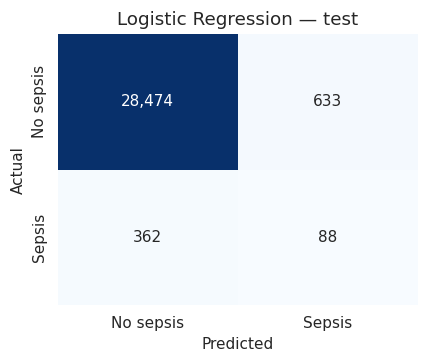

CPU times: user 1min 39s, sys: 68.2 ms, total: 1min 39s
Wall time: 1min 39s


In [ ]:
%%time
lr = LogisticRegression(
    penalty="l2",              # L2 regularisation — shrinks coefficients, reduces overfitting on correlated features
    C=0.1,                     # inverse of regularisation strength — smaller C = stronger penalty
    solver="saga",             # solver capable of handling large datasets efficiently
    max_iter=400,              # max optimisation iterations before giving up
    class_weight="balanced",   # automatically upweights the rare sepsis class instead of ignoring it
    n_jobs=-1,                 # use all available CPU cores
    random_state=RANDOM_SEED)  # reproducibility
lr.fit(Str, ytr)               # train on the SCALED training features

evaluate("Logistic Regression", lr.predict_proba(Sva)[:,1], lr.predict_proba(Ste)[:,1])
# predict_proba returns [P(no sepsis), P(sepsis)] per row — we take column [:,1] = P(sepsis)
plot_cm("Logistic Regression")

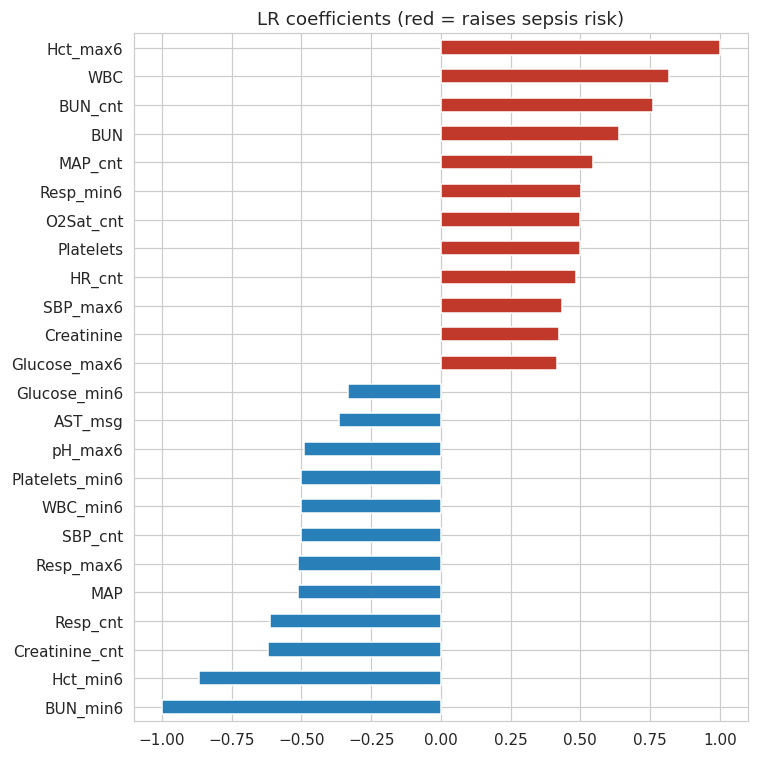

In [ ]:
# Interpretability: which features push the prediction toward/away from sepsis?
coef = pd.Series(lr.coef_[0], index=Str.columns).sort_values()   # model's learned weight for each feature
top = pd.concat([coef.head(12), coef.tail(12)])                   # 12 most negative + 12 most positive weights
top.plot.barh(figsize=(7,7), color=np.where(top > 0, "#c0392b", "#2980b9"))   # red = raises risk, blue = lowers risk
plt.title("LR coefficients (red = raises sepsis risk)"); plt.tight_layout(); plt.show()

# Linear SVC

--- SVM (Linear) ---
  Accuracy  : 0.9643
  Precision : 0.1174
  Recall    : 0.2067
  F1        : 0.1498
  ROC_AUC   : 0.7768
  PR_AUC    : 0.0941
  Threshold : 0.8686
  Confusion [[TN FP][FN TP]]:
 [[28408   699]
 [  357    93]]


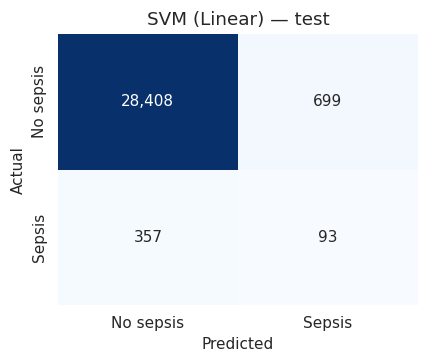

CPU times: user 46.8 s, sys: 245 ms, total: 47 s
Wall time: 47.1 s


In [ ]:
%%time
# LinearSVC: a linear-kernel SVM with a fast solver, can handle the full dataset
svm_lin = LinearSVC(
    C=0.01,                    # regularisation strength — smaller = stronger penalty on large weights
    class_weight="balanced",   # upweight the rare sepsis class
    max_iter=5000,             # allow more iterations to converge on this large dataset
    dual=False,                # faster when there are more rows than features
    random_state=RANDOM_SEED)
svm_lin.fit(Str, ytr)          # train on scaled features

# LinearSVC has no predict_proba, so we use decision_function (a raw score, higher = more sepsis-like)
evaluate("SVM (Linear)", svm_lin.decision_function(Sva), svm_lin.decision_function(Ste))
plot_cm("SVM (Linear)")

In [ ]:
%%time
# Kernel (RBF) SVM: much more powerful but far too slow to train on 1M+ rows -> use a subsample
SUB = 120_000                                       # target subsample size
idx_pos, idx_neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]   # positions of positive/negative rows
rs = np.random.RandomState(RANDOM_SEED)
n_neg = min(len(idx_neg), SUB - len(idx_pos))        # keep ALL positives, fill the rest with negatives
sub = np.concatenate([idx_pos, rs.choice(idx_neg, n_neg, replace=False)])   # combine indices
rs.shuffle(sub)                                       # shuffle so rows aren't grouped by class
print("subsample:", len(sub), "rows |", ytr[sub].sum(), "positives")

svm_rbf = SVC(
    kernel="rbf",               # radial-basis-function kernel — captures non-linear boundaries
    C=1.0, gamma="scale",       # standard default settings
    class_weight="balanced",
    cache_size=1000,            # more memory for kernel computations = faster
    random_state=RANDOM_SEED)
svm_rbf.fit(Str.iloc[sub], ytr[sub])                  # train only on the subsample

evaluate("SVM (RBF, subsampled)", svm_rbf.decision_function(Sva), svm_rbf.decision_function(Ste))

subsample: 120000 rows | 2157 positives
--- SVM (RBF, subsampled) ---
  Accuracy  : 0.9175
  Precision : 0.0498
  Recall    : 0.2444
  F1        : 0.0828
  ROC_AUC   : 0.6827
  PR_AUC    : 0.0339
  Threshold : -0.4847
  Confusion [[TN FP][FN TP]]:
 [[27010  2097]
 [  340   110]]
CPU times: user 23min 54s, sys: 2.23 s, total: 23min 56s
Wall time: 24min 15s


{'Model': 'SVM (RBF, subsampled)',
 'Accuracy': 0.9175491423351491,
 'Precision': 0.04984141368373358,
 'Recall': 0.24444444444444444,
 'F1': 0.08280015054572827,
 'ROC_AUC': np.float64(0.6827252703626084),
 'PR_AUC': np.float64(0.0338557956397876),
 'Threshold': -0.48465432987152696}

# Random Forest Classifier

--- Random Forest ---
  Accuracy  : 0.9578
  Precision : 0.0921
  Recall    : 0.2000
  F1        : 0.1261
  ROC_AUC   : 0.7834
  PR_AUC    : 0.0601
  Threshold : 0.3380
  Confusion [[TN FP][FN TP]]:
 [[28220   887]
 [  360    90]]


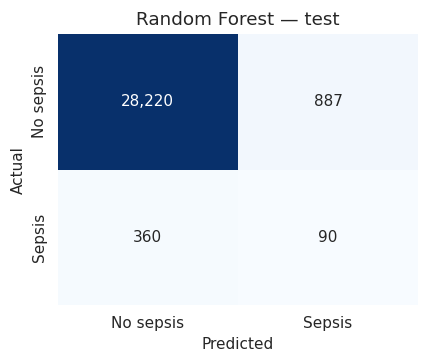

CPU times: user 3min 35s, sys: 557 ms, total: 3min 35s
Wall time: 2min 3s


In [ ]:
%%time
rf = RandomForestClassifier(
    n_estimators=300,               # number of individual decision trees in the forest
    min_samples_leaf=20,            # each leaf must have at least 20 samples — prevents overfitting to single hours
    max_features="sqrt",            # each tree split only considers a random subset of features (adds diversity)
    class_weight="balanced_subsample",   # reweights classes within each tree's bootstrap sample
    n_jobs=-1,                      # use all CPU cores — trees train in parallel
    random_state=RANDOM_SEED)
rf.fit(Xtr, ytr)                    # trees don't need scaled data, so we use the UNSCALED Xtr

evaluate("Random Forest", rf.predict_proba(Xva)[:,1], rf.predict_proba(Xte)[:,1])
plot_cm("Random Forest")

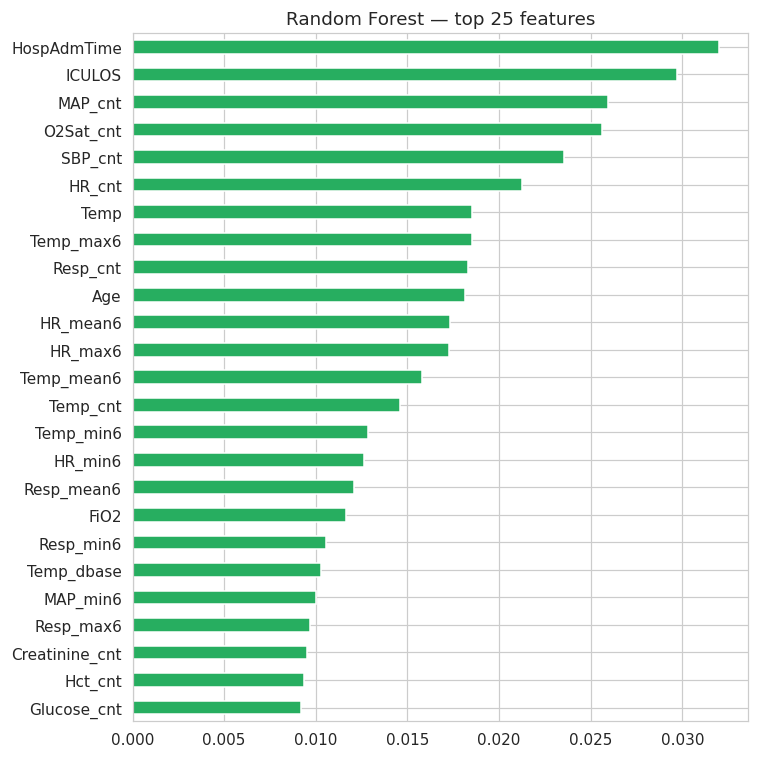

,importance
HospAdmTime,0.031989
ICULOS,0.029716
MAP_cnt,0.025926
O2Sat_cnt,0.025601
SBP_cnt,0.023524
HR_cnt,0.021267
Temp,0.018525
Temp_max6,0.018509
Resp_cnt,0.018314
Age,0.018122


In [ ]:
# feature importance: how much each feature reduced prediction error, averaged across all trees
imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
imp.head(25).iloc[::-1].plot.barh(figsize=(7,7), color="#27ae60")   # top 25, reversed so biggest is at top
plt.title("Random Forest — top 25 features"); plt.tight_layout(); plt.show()
imp.head(15).to_frame("importance")   # display as a table too

In [ ]:
%%time
# ICULOS (hours since admission) is usually the #1 feature but isn't physiology — check how much we rely on it
rf_abl = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                                class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED)
rf_abl.fit(Xtr.drop(columns=["ICULOS"]), ytr)      # train WITHOUT the ICULOS column
evaluate("Random Forest (no ICULOS)",
         rf_abl.predict_proba(Xva.drop(columns=["ICULOS"]))[:,1],
         rf_abl.predict_proba(Xte.drop(columns=["ICULOS"]))[:,1])

--- Random Forest (no ICULOS) ---
  Accuracy  : 0.9435
  Precision : 0.0793
  Recall    : 0.2556
  F1        : 0.1210
  ROC_AUC   : 0.7791
  PR_AUC    : 0.0569
  Threshold : 0.2663
  Confusion [[TN FP][FN TP]]:
 [[27771  1336]
 [  335   115]]
CPU times: user 2min 22s, sys: 357 ms, total: 2min 22s
Wall time: 1min 21s


{'Model': 'Random Forest (no ICULOS)',
 'Accuracy': 0.9434651689955003,
 'Precision': 0.07925568573397657,
 'Recall': 0.25555555555555554,
 'F1': 0.12098895318253551,
 'ROC_AUC': np.float64(0.7791271668136339),
 'PR_AUC': np.float64(0.056926648871921184),
 'Threshold': 0.2663213780705652}

  depth= 6 leaf= 20  val ROC-AUC=0.7104
  depth= 6 leaf= 50  val ROC-AUC=0.7103
  depth= 6 leaf=200  val ROC-AUC=0.7068
  depth= 8 leaf= 20  val ROC-AUC=0.6859
  depth= 8 leaf= 50  val ROC-AUC=0.6854
  depth= 8 leaf=200  val ROC-AUC=0.6788
  depth=10 leaf= 20  val ROC-AUC=0.6751
  depth=10 leaf= 50  val ROC-AUC=0.6709
  depth=10 leaf=200  val ROC-AUC=0.6269
  depth=12 leaf= 20  val ROC-AUC=0.6417
  depth=12 leaf= 50  val ROC-AUC=0.6352
  depth=12 leaf=200  val ROC-AUC=0.6321
  depth=16 leaf= 20  val ROC-AUC=0.6202
  depth=16 leaf= 50  val ROC-AUC=0.6135
  depth=16 leaf=200  val ROC-AUC=0.6491

best: depth=6 leaf=20 val ROC-AUC=0.7104
--- Decision Tree ---
  Accuracy  : 0.9317
  Precision : 0.0899
  Recall    : 0.3822
  F1        : 0.1456
  ROC_AUC   : 0.6967
  PR_AUC    : 0.0605
  Threshold : 0.8523
  Confusion [[TN FP][FN TP]]:
 [[27366  1741]
 [  278   172]]


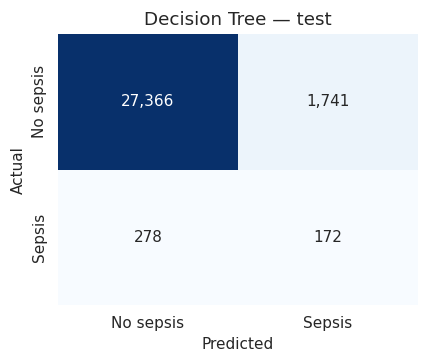

CPU times: user 1min 33s, sys: 55.4 ms, total: 1min 33s
Wall time: 1min 34s


In [ ]:
%%time
best = None                                         # will hold (score, depth, leaf_size, trained_model) of the best combo
for depth in [6, 8, 10, 12, 16]:                    # try several max tree depths
    for leaf in [20, 50, 200]:                       # and several minimum leaf sizes
        dt = DecisionTreeClassifier(
            max_depth=depth,           # deeper trees fit more detail but overfit more
            min_samples_leaf=leaf,     # larger leaves = simpler, more generalisable tree
            class_weight="balanced",   # upweight the rare sepsis class
            random_state=RANDOM_SEED)
        dt.fit(Xtr, ytr)               # train this combination
        a = roc_auc_score(yva, dt.predict_proba(Xva)[:,1])   # score it on VALIDATION (never test, during tuning)
        print(f"  depth={depth:2d} leaf={leaf:3d}  val ROC-AUC={a:.4f}")
        if best is None or a > best[0]:               # keep track of the best-performing combination
            best = (a, depth, leaf, dt)
print(f"\nbest: depth={best[1]} leaf={best[2]} val ROC-AUC={best[0]:.4f}")
dt = best[3]                                         # use the winning tree going forward

evaluate("Decision Tree", dt.predict_proba(Xva)[:,1], dt.predict_proba(Xte)[:,1])
plot_cm("Decision Tree")

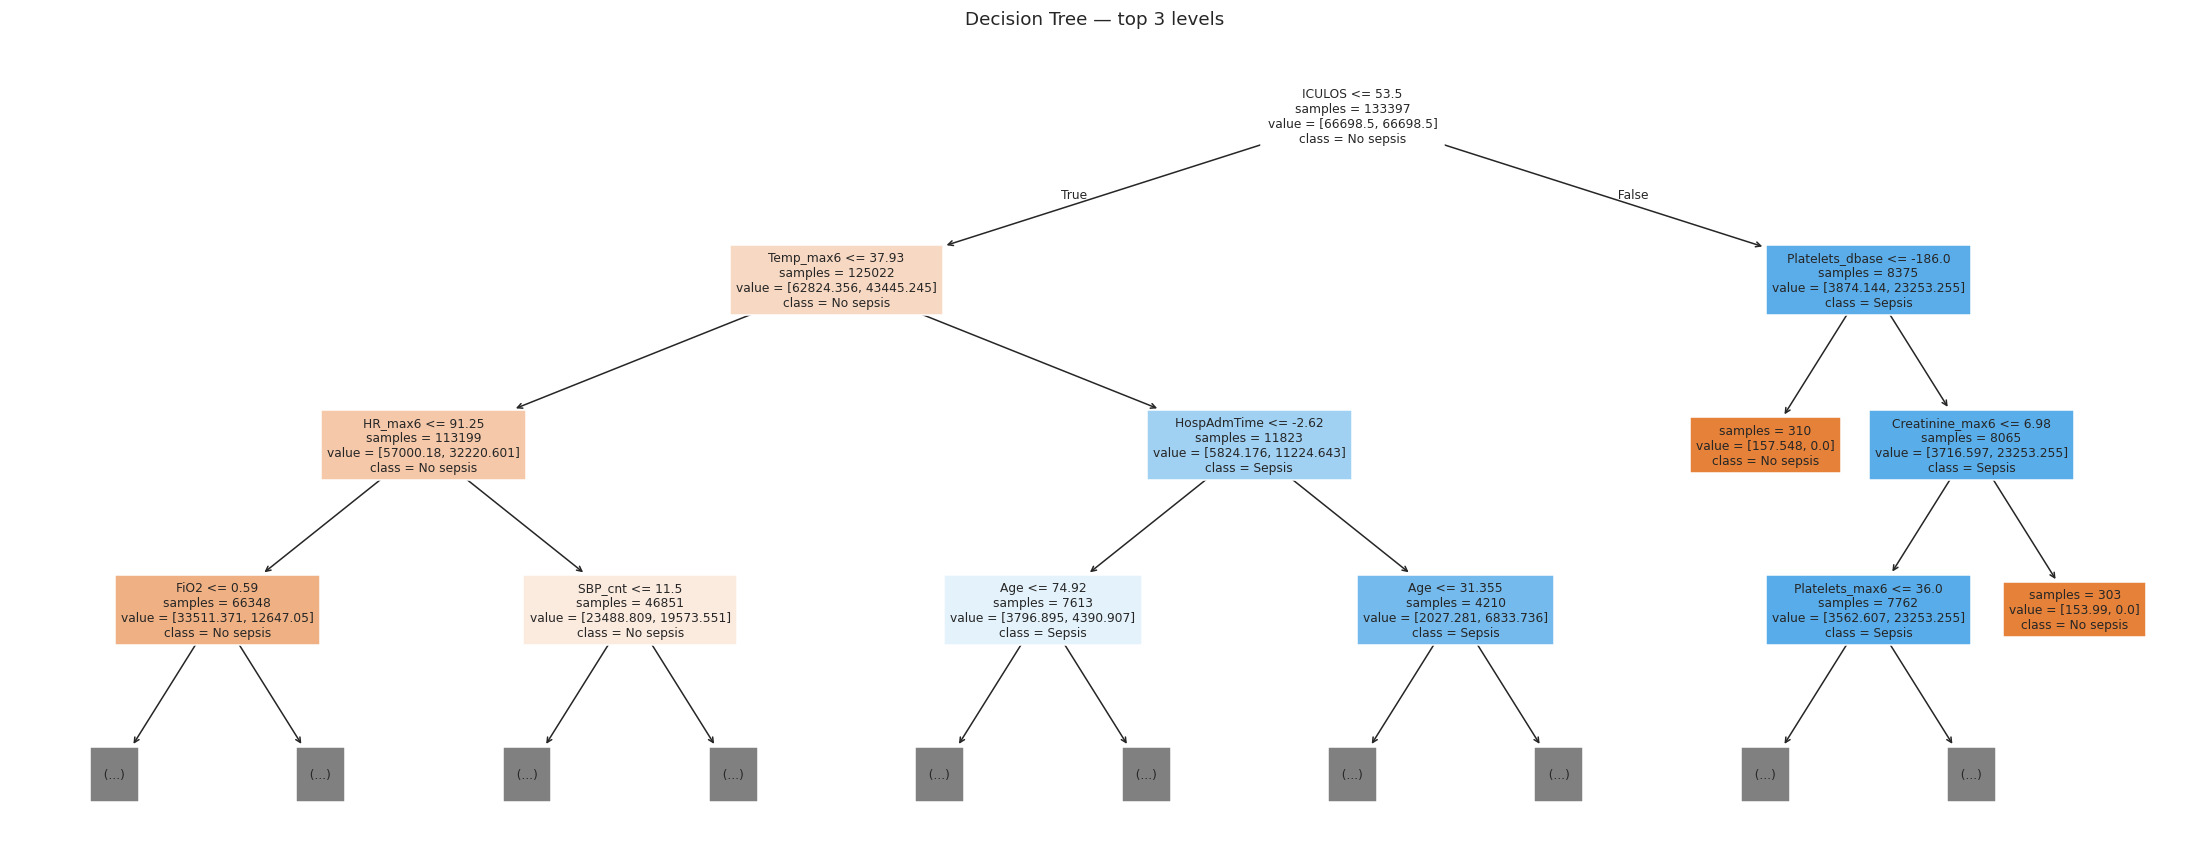

In [ ]:
from sklearn.tree import plot_tree                   # utility to visually draw a decision tree
plt.figure(figsize=(20,8))
plot_tree(dt, max_depth=3,                            # only show the top 3 levels (full tree is unreadable)
          feature_names=list(Xtr.columns),
          class_names=["No sepsis","Sepsis"],
          filled=True,                                 # colour boxes by predicted class
          fontsize=8, impurity=False)
plt.title("Decision Tree — top 3 levels"); plt.tight_layout(); plt.show()

In [ ]:
# collect every model's metrics (excluding the raw score arrays and confusion matrices) into one table
cmp = pd.DataFrame([{k: v for k, v in r.items() if k not in ("scores_te","cm")}
                    for r in RESULTS.values()]).set_index("Model")
cmp = cmp.sort_values("ROC_AUC", ascending=False)     # rank models by ROC-AUC, the primary metric for imbalanced data
display(cmp.style.format("{:.4f}").background_gradient(cmap="Greens", subset=["ROC_AUC","PR_AUC","F1"]))
cmp.to_csv("/content/model_comparison.csv")            # save the table to disk
best_model = cmp.index[0]                               # name of the top-scoring model
print("\nBest by ROC-AUC:", best_model)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
Model,,,,,,,
Random Forest,0.9578,0.0921,0.2000,0.1261,0.7834,0.0601,0.3380
Logistic Regression,0.9663,0.1221,0.1956,0.1503,0.7797,0.0960,0.9156
Random Forest (no ICULOS),0.9435,0.0793,0.2556,0.1210,0.7791,0.0569,0.2663
SVM (Linear),0.9643,0.1174,0.2067,0.1498,0.7768,0.0941,0.8686
Decision Tree,0.9317,0.0899,0.3822,0.1456,0.6967,0.0605,0.8523
"SVM (RBF, subsampled)",0.9175,0.0498,0.2444,0.0828,0.6827,0.0339,-0.4847



Best by ROC-AUC: Random Forest


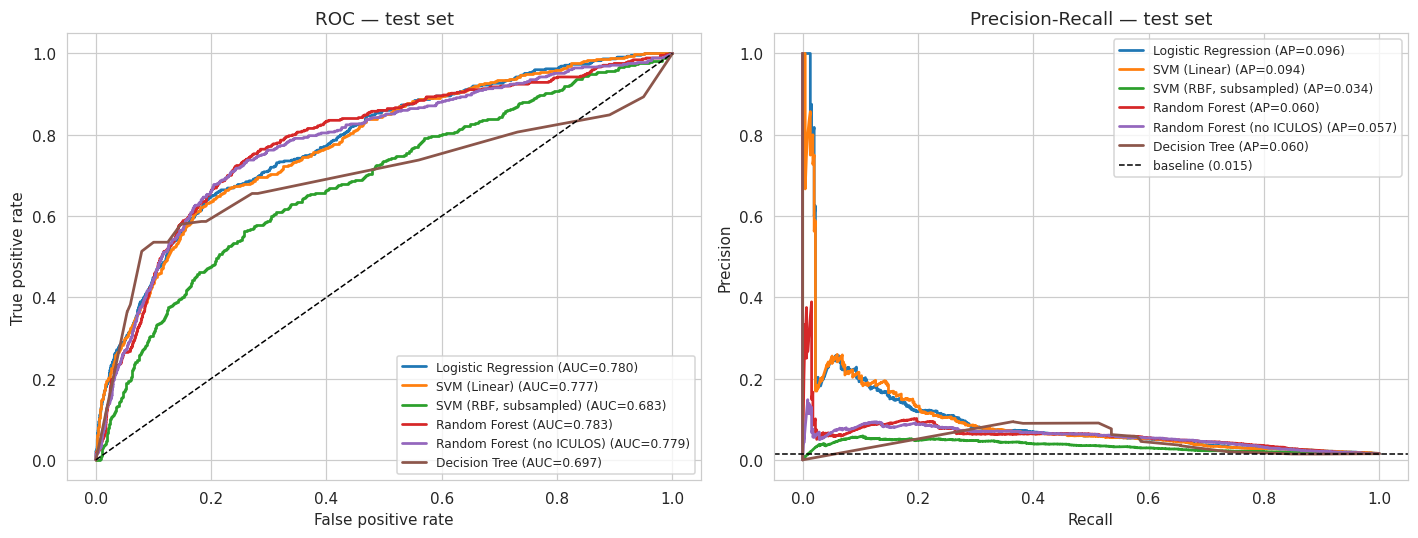

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13,5))            # two side-by-side plots
for name, r in RESULTS.items():                          # loop over every model's saved results
    fpr, tpr, _ = roc_curve(yte, r["scores_te"])          # false-positive-rate, true-positive-rate at every threshold
    ax[0].plot(fpr, tpr, lw=1.8, label=f"{name} (AUC={r['ROC_AUC']:.3f})")
    p, rc, _ = precision_recall_curve(yte, r["scores_te"])   # precision & recall at every threshold
    ax[1].plot(rc, p, lw=1.8, label=f"{name} (AP={r['PR_AUC']:.3f})")
ax[0].plot([0,1],[0,1],"k--",lw=1)                        # diagonal = random-guessing baseline for ROC
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC — test set"); ax[0].legend(fontsize=8)
ax[1].axhline(yte.mean(), color="k", ls="--", lw=1, label=f"baseline ({yte.mean():.3f})")  # no-skill baseline for PR
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall — test set"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
def early_warning(name, thr=None, min_consecutive=1):
    # name = which model's results to analyse (must already exist in RESULTS)
    # thr  = score cutoff to count as an "alarm" -- defaults to that model's own tuned threshold
    # min_consecutive = require this many consecutive alarm-hours before counting it as a real alert
    #                    (reduces false alarms from single noisy readings)
    r = RESULTS[name]
    thr = r["Threshold"] if thr is None else thr        # use the model's tuned threshold unless overridden
    d = meta_te.copy()                                    # work on a copy of the test-set metadata (patient, hour, label)
    d["alarm"] = (r["scores_te"] >= thr).astype(int)      # 1 if the model's score crosses the threshold at this hour

    leads, detected, fa, n_sep, n_non = [], 0, 0, 0, 0     # accumulators across all patients:
    # leads    = list of lead times (hours of warning) for every septic patient we caught
    # detected = count of septic patients we caught at least once
    # fa       = count of non-septic patients who got at least one false alarm
    # n_sep    = total septic patients in the test set
    # n_non    = total non-septic patients in the test set

    for _, g in d.groupby("patient", observed=True, sort=False):   # process one patient's full timeline at a time
        a = g["alarm"].values                              # this patient's hour-by-hour alarm flags (0/1 array)

        if min_consecutive > 1:
            # sliding window: find the first position where `min_consecutive` alarms occur in a row
            k = np.convolve(a, np.ones(min_consecutive, int), "valid") == min_consecutive
            first = np.argmax(k) + min_consecutive - 1 if k.any() else None   # index of the LAST hour in that streak
        else:
            # simplest case: just the first hour where an alarm fired at all
            first = int(np.argmax(a)) if a.any() else None

        if g["SepsisLabel"].max() == 1:                     # this patient DID become septic at some point
            n_sep += 1
            # SepsisLabel is already shifted 6h earlier than true clinical onset by the dataset creators,
            # so we add 6 back to get the actual onset hour
            onset = g["ICULOS"].values[np.argmax(g["SepsisLabel"].values)] + 6
            if first is not None:                            # the model raised an alarm at some point for this patient
                detected += 1
                # lead time = how many hours BEFORE onset the alarm fired (positive = early warning given)
                leads.append(onset - g["ICULOS"].values[first])
        else:                                                 # this patient never became septic
            n_non += 1
            fa += first is not None                          # did the model still raise an alarm? (a false alarm)

    leads = np.array(leads, dtype=float)                     # convert list of lead times to a numpy array for stats
    return dict(
        Model=name,
        Septic_patients=n_sep,
        Detected=detected,
        Detection_rate=detected/max(n_sep,1),                # fraction of septic patients caught at all -- higher is better
        Median_lead_h=np.median(leads) if len(leads) else np.nan,   # typical hours of warning given before onset
        Mean_lead_h=leads.mean() if len(leads) else np.nan,
        False_alarm_rate=fa/max(n_non,1))                    # fraction of healthy patients wrongly alarmed -- lower is better


# run the function above once for every trained model, and lay the results out in a table
ew = pd.DataFrame([early_warning(n) for n in RESULTS]).set_index("Model")
display(ew.style.format({"Detection_rate":"{:.3f}","Median_lead_h":"{:.1f}",
                         "Mean_lead_h":"{:.1f}","False_alarm_rate":"{:.3f}"}))

,Septic_patients,Detected,Detection_rate,Median_lead_h,Mean_lead_h,False_alarm_rate
Model,,,,,,
Logistic Regression,48,19,0.396,28.0,56.0,0.053
SVM (Linear),48,19,0.396,31.0,58.8,0.061
"SVM (RBF, subsampled)",48,31,0.646,27.0,61.4,0.416
Random Forest,48,24,0.500,27.5,67.6,0.215
Random Forest (no ICULOS),48,34,0.708,45.0,66.3,0.406
Decision Tree,48,21,0.438,38.0,69.1,0.110


In [ ]:
# Requiring several consecutive alarm-hours (instead of just 1) trades a little detection
# for far fewer false alarms -- this sweep shows that trade-off explicitly for your best model
pd.DataFrame([early_warning(best_model, min_consecutive=k) | {"consecutive_h": k}
              for k in [1,2,3,4,6]]).set_index("consecutive_h")[
    ["Detection_rate","Median_lead_h","False_alarm_rate"]].round(3)

,Detection_rate,Median_lead_h,False_alarm_rate
consecutive_h,,,
1,0.500,27.5,0.215
2,0.271,38.0,0.019
3,0.271,34.0,0.009
4,0.250,34.5,0.007
6,0.208,32.5,0.003


In [ ]:
# A single F1-optimal threshold is one arbitrary choice. This shows what happens at other
# operating points, so you can discuss the precision/recall trade-off explicitly in your report.
rows = []
score = RESULTS[best_model]["scores_te"]                # test-set scores from the best model
for q in [50, 80, 90, 95, 97, 98, 99, 99.5]:             # q = percentile used as the alarm threshold
    thr = np.percentile(score, q)                         # e.g. q=99 -> only the top 1% of scores trigger an alarm
    pr = (score >= thr).astype(int)                        # apply that threshold
    rows.append(dict(alerted_pct=100-q, threshold=thr,     # alerted_pct = % of hours that would trigger an alarm
                     Precision=precision_score(yte, pr, zero_division=0),
                     Recall=recall_score(yte, pr, zero_division=0),
                     F1=f1_score(yte, pr, zero_division=0)))
pd.DataFrame(rows).set_index("alerted_pct").round(4)

,threshold,Precision,Recall,F1
alerted_pct,,,,
50.0,0.0493,0.0262,0.8600,0.0508
20.0,0.1065,0.0494,0.6489,0.0918
10.0,0.1708,0.0646,0.4244,0.1122
5.0,0.2631,0.0771,0.2533,0.1183
3.0,0.3609,0.1003,0.1978,0.1331
2.0,0.4484,0.0811,0.1067,0.0921
1.0,0.5353,0.0642,0.0422,0.0509
0.5,0.5893,0.0676,0.0222,0.0334


In [ ]:
import joblib                                             # library for saving/loading sklearn models to disk
os.makedirs("/content/models", exist_ok=True)              # folder to hold everything we're about to save

# save the imputer + scaler + feature list TOGETHER -- a model is useless on new data without these
joblib.dump({"imputer": imputer, "scaler": scaler, "features": list(X.columns)},
            "/content/models/preprocessing.joblib")

# save each trained model under its own filename
for nm, mdl in [("logistic_regression", lr), ("svm_linear", svm_lin),
                ("random_forest", rf), ("decision_tree", dt)]:
    joblib.dump(mdl, f"/content/models/{nm}.joblib")

cmp.to_csv("/content/models/results.csv")                  # also save the comparison table as csv
print(os.listdir("/content/models"))                        # confirm everything got saved

['preprocessing.joblib', 'decision_tree.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'results.csv', 'svm_linear.joblib']


In [ ]:
# optional: download the saved models + results to your own computer as a zip
!zip -r -q /content/models.zip /content/models
from google.colab import files
files.download("/content/models.zip")                       # triggers a browser download

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%time
rs = np.random.RandomState(RANDOM_SEED)
sub = rs.choice(len(X), size=min(300_000, len(X)), replace=False)   # subsample for speed (effect is the same at any size)
Xp = pd.DataFrame(imputer.transform(X.iloc[sub]), columns=X.columns).astype("float32")
yp = y[sub]

# BAD: balance the whole dataset, THEN split by row -- this leaks test-patient information into training
Xb, yb = SMOTE(random_state=RANDOM_SEED).fit_resample(Xp, yp)   # <-- removed n_jobs=-1
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25,
                                              stratify=yb, random_state=RANDOM_SEED)
rf_leak = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, n_jobs=-1,
                                 random_state=RANDOM_SEED).fit(Xb_tr, yb_tr)
pl, pp = rf_leak.predict(Xb_te), rf_leak.predict_proba(Xb_te)[:,1]

print("=== Paper-style protocol (row shuffle + SMOTE before split) ===")
print(f"  Accuracy : {accuracy_score(yb_te, pl):.4f}")
print(f"  F1       : {f1_score(yb_te, pl):.4f}")
print(f"  ROC-AUC  : {roc_auc_score(yb_te, pp):.4f}")
print("\nCompare this to your honest patient-level result in Cell 14 -- the gap is caused by leakage, not a better model.")

=== Paper-style protocol (row shuffle + SMOTE before split) ===
  Accuracy : 0.9987
  F1       : 0.9987
  ROC-AUC  : 0.9999

Compare this to your honest patient-level result in Cell 14 -- the gap is caused by leakage, not a better model.
CPU times: user 14min 32s, sys: 1.7 s, total: 14min 33s
Wall time: 8min 48s


In [ ]:
%%time
sm = SMOTE(random_state=RANDOM_SEED, sampling_strategy=0.3)   # <-- removed n_jobs=-1
s = np.random.RandomState(RANDOM_SEED).choice(len(Xtr), size=min(400_000, len(Xtr)), replace=False)
Xs, ys = sm.fit_resample(Xtr.iloc[s], ytr[s])
print("after SMOTE:", Xs.shape, "positive rate {:.3f}".format(ys.mean()))

rf_sm = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                               n_jobs=-1, random_state=RANDOM_SEED).fit(Xs, ys)
evaluate("Random Forest + SMOTE (correct)", rf_sm.predict_proba(Xva)[:,1],
         rf_sm.predict_proba(Xte)[:,1])

after SMOTE: (170612, 164) positive rate 0.231
--- Random Forest + SMOTE (correct) ---
  Accuracy  : 0.9557
  Precision : 0.0996
  Recall    : 0.2378
  F1        : 0.1404
  ROC_AUC   : 0.7922
  PR_AUC    : 0.0758
  Threshold : 0.2447
  Confusion [[TN FP][FN TP]]:
 [[28140   967]
 [  343   107]]
CPU times: user 4min 47s, sys: 532 ms, total: 4min 48s
Wall time: 2min 42s


{'Model': 'Random Forest + SMOTE (correct)',
 'Accuracy': 0.9556788578001827,
 'Precision': 0.09962756052141528,
 'Recall': 0.23777777777777778,
 'F1': 0.14041994750656167,
 'ROC_AUC': np.float64(0.7922163435294297),
 'PR_AUC': np.float64(0.07576872103591631),
 'Threshold': 0.24467724791650816}

In [ ]:
%%time
hosp = meta["hospital"].values
mA, mB = (hosp == "A"), (hosp == "B")

if mA.sum() and mB.sum():
    # keep_empty_features=True stops the imputer from silently dropping columns that are
    # 100% missing within hospital A -- without this, output column count can mismatch X.columns
    impA = SimpleImputer(strategy="median", keep_empty_features=True)
    XA = pd.DataFrame(impA.fit_transform(X[mA]), columns=X.columns).astype("float32")
    XB = pd.DataFrame(impA.transform(X[mB]),     columns=X.columns).astype("float32")
    yA, yB = y[mA], y[mB]

    rf_ext = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                                    class_weight="balanced_subsample", n_jobs=-1,
                                    random_state=RANDOM_SEED).fit(XA, yA)
    sB = rf_ext.predict_proba(XB)[:,1]

    pa = meta[mA].groupby("patient", observed=True)["SepsisLabel"].max()
    a_tr, a_te = train_test_split(pa.index, test_size=0.2, stratify=pa.values, random_state=RANDOM_SEED)
    mm = meta[mA]["patient"].isin(set(a_te)).values
    rf_in = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                                   class_weight="balanced_subsample", n_jobs=-1,
                                   random_state=RANDOM_SEED).fit(XA[~mm], yA[~mm])
    sA = rf_in.predict_proba(XA[mm])[:,1]

    print("Internal (A -> held-out A): ROC-AUC {:.4f} | PR-AUC {:.4f}".format(
        roc_auc_score(yA[mm], sA), average_precision_score(yA[mm], sA)))
    print("External (A -> B, unseen) : ROC-AUC {:.4f} | PR-AUC {:.4f}".format(
        roc_auc_score(yB, sB), average_precision_score(yB, sB)))
    print("\nThe gap between these two numbers is your estimate of the real-world cost of deploying")
    print("at a hospital the model was never trained on.")
else:
    print("Need both hospital A and hospital B rows present in your data for this experiment.")

Internal (A -> held-out A): ROC-AUC 0.8224 | PR-AUC 0.1259
External (A -> B, unseen) : ROC-AUC 0.7509 | PR-AUC 0.0484

The gap between these two numbers is your estimate of the real-world cost of deploying
at a hospital the model was never trained on.
CPU times: user 2min 55s, sys: 511 ms, total: 2min 56s
Wall time: 1min 48s


In [ ]:
print("="*70)
print("SUMMARY -- copy these numbers into your report")
print("="*70)
print("\n1. Model comparison (patient-level split, honest evaluation):")
print(cmp[["Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC"]].round(4).to_string())
print(f"\n2. Best model: {best_model}")
print(f"\n3. Early-warning performance for {best_model}:")
print(ew.loc[[best_model]].round(3).to_string())
print("\n4. Interpretation:")
print(f"   - Row-level accuracy alone is misleading at {100*yte.mean():.1f}% sepsis prevalence")
print(f"   - ROC-AUC and PR-AUC are the metrics that matter here")
print(f"   - Compare Cell 14 (honest) vs Cell 18 (paper-style) to show the leakage effect")

SUMMARY -- copy these numbers into your report

1. Model comparison (patient-level split, honest evaluation):
                           Accuracy  Precision  Recall      F1  ROC_AUC  PR_AUC
Model                                                                          
Random Forest                0.9578     0.0921  0.2000  0.1261   0.7834  0.0601
Logistic Regression          0.9663     0.1221  0.1956  0.1503   0.7797  0.0960
Random Forest (no ICULOS)    0.9435     0.0793  0.2556  0.1210   0.7791  0.0569
SVM (Linear)                 0.9643     0.1174  0.2067  0.1498   0.7768  0.0941
Decision Tree                0.9317     0.0899  0.3822  0.1456   0.6967  0.0605
SVM (RBF, subsampled)        0.9175     0.0498  0.2444  0.0828   0.6827  0.0339

2. Best model: Random Forest

3. Early-warning performance for Random Forest:
               Septic_patients  Detected  Detection_rate  Median_lead_h  Mean_lead_h  False_alarm_rate
Model                                                               

In [ ]:
def predict_new_patient(hourly_records, verbose=True):
    """
    hourly_records: a list of dicts, one dict per hour of ICU data you have for this patient.
                     You don't need to fill in every field -- unknown values are left out (treated as missing).
                     Provide as many hours as you have; even 1 hour works, but more hours let the model
                     compute proper trend features (rising/falling HR, etc.) instead of guessing.
    """
    df = pd.DataFrame(hourly_records)                     # turn the list of dicts into a small table

    # make sure every column the pipeline expects exists, even if the user didn't provide it
    for c in VITALS + LABS + STATIC:
        if c not in df.columns:
            df[c] = np.nan                                  # missing = NaN, same as the real dataset's convention

    df["patient"] = "NEW_PATIENT"                           # a fake patient ID, needed by build_features' groupby

    # if the user didn't supply hour numbers, assume rows are already in chronological order
    if "ICULOS" not in df.columns or df["ICULOS"].isna().all():
        df["ICULOS"] = np.arange(1, len(df) + 1)

    df["SepsisLabel"] = 0                                    # placeholder column -- required by build_features, unused here

    # run the EXACT SAME feature engineering used during training (Cell 6)
    X_new, _, _ = build_features(df)

    # align columns to match the training feature order exactly -- reindex fills any missing
    # engineered columns with NaN, which the imputer will then handle just like it does for real gaps
    X_new = X_new.reindex(columns=list(X.columns))

    X_last = X_new.iloc[[-1]]                                 # take only the MOST RECENT hour -- that's what we predict on

    # run through the same imputer + scaler fitted during training
    X_imp = pd.DataFrame(imputer.transform(X_last), columns=X.columns)
    X_scl = pd.DataFrame(scaler.transform(X_imp),    columns=X.columns)

    # get a probability / risk score from each of the four trained models
    results = {
        "Logistic Regression": lr.predict_proba(X_scl)[0, 1],
        "SVM (Linear)":        1 / (1 + np.exp(-svm_lin.decision_function(X_scl)[0])),  # sigmoid turns raw score into 0-1 range
        "Random Forest":       rf.predict_proba(X_imp)[0, 1],
        "Decision Tree":       dt.predict_proba(X_imp)[0, 1],
    }

    if verbose:
        print(f"{'Model':22s} {'Sepsis risk':>12s}  {'Verdict':>10s}")
        print("-" * 48)
        for name, prob in results.items():
            thr = RESULTS[name]["Threshold"] if name in RESULTS else 0.5    # use each model's tuned threshold
            # NOTE: SVM's threshold was tuned on decision_function scores, not sigmoid probabilities --
            # so for SVM we compare the raw decision_function value against its threshold instead
            if name == "SVM (Linear)":
                raw = svm_lin.decision_function(X_scl)[0]
                verdict = "SEPSIS RISK" if raw >= RESULTS[name]["Threshold"] else "low risk"
            else:
                verdict = "SEPSIS RISK" if prob >= thr else "low risk"
            print(f"{name:22s} {prob*100:11.1f}%  {verdict:>10s}")

    return results

print("predict_new_patient() ready")

predict_new_patient() ready


In [ ]:
def predict_new_patient(hourly_records, verbose=True):
    """
    hourly_records: a list of dicts, one dict per hour of ICU data you have for this patient.
                     You don't need to fill in every field -- unknown values are left out (treated as missing).
                     Provide as many hours as you have; even 1 hour works, but more hours let the model
                     compute proper trend features (rising/falling HR, etc.) instead of guessing.
    """
    df = pd.DataFrame(hourly_records)                     # turn the list of dicts into a small table

    # make sure every column the pipeline expects exists, even if the user didn't provide it
    for c in VITALS + LABS + STATIC:
        if c not in df.columns:
            df[c] = np.nan                                  # missing = NaN, same as the real dataset's convention

    df["patient"] = "NEW_PATIENT"                           # a fake patient ID, needed by build_features' groupby
    df["hospital"] = "A"                                     # placeholder -- build_features expects this column to
                                                                # exist, but its value has no effect on the prediction

    # if the user didn't supply hour numbers, assume rows are already in chronological order
    if "ICULOS" not in df.columns or df["ICULOS"].isna().all():
        df["ICULOS"] = np.arange(1, len(df) + 1)

    df["SepsisLabel"] = 0                                    # placeholder column -- required by build_features, unused here

    # run the EXACT SAME feature engineering used during training (Cell 6)
    X_new, _, _ = build_features(df)

    # align columns to match the training feature order exactly -- reindex fills any missing
    # engineered columns with NaN, which the imputer will then handle just like it does for real gaps
    X_new = X_new.reindex(columns=list(X.columns))

    X_last = X_new.iloc[[-1]]                                 # take only the MOST RECENT hour -- that's what we predict on

    # run through the same imputer + scaler fitted during training
    X_imp = pd.DataFrame(imputer.transform(X_last), columns=X.columns)
    X_scl = pd.DataFrame(scaler.transform(X_imp),    columns=X.columns)

    # get a probability / risk score from each of the four trained models
    results = {
        "Logistic Regression": lr.predict_proba(X_scl)[0, 1],
        "SVM (Linear)":        1 / (1 + np.exp(-svm_lin.decision_function(X_scl)[0])),  # sigmoid turns raw score into 0-1 range
        "Random Forest":       rf.predict_proba(X_imp)[0, 1],
        "Decision Tree":       dt.predict_proba(X_imp)[0, 1],
    }

    if verbose:
        print(f"{'Model':22s} {'Sepsis risk':>12s}  {'Verdict':>10s}")
        print("-" * 48)
        for name, prob in results.items():
            thr = RESULTS[name]["Threshold"] if name in RESULTS else 0.5
            if name == "SVM (Linear)":
                raw = svm_lin.decision_function(X_scl)[0]
                verdict = "SEPSIS RISK" if raw >= RESULTS[name]["Threshold"] else "low risk"
            else:
                verdict = "SEPSIS RISK" if prob >= thr else "low risk"
            print(f"{name:22s} {prob*100:11.1f}%  {verdict:>10s}")

    return results

print("predict_new_patient() ready")

predict_new_patient() ready


In [ ]:
# EDIT this to the patient's actual hourly readings, oldest hour first.
# Each dict is one hour. Fields you don't have for a given hour can simply be left out.
new_patient_history = [
    {"HR": 92,  "MAP": 78, "Resp": 18, "Temp": 37.0, "O2Sat": 97, "SBP": 118, "WBC": 9.1,
     "Age": 67, "Gender": 1, "Unit1": 1, "Unit2": 0, "HospAdmTime": -5, "ICULOS": 1},
    {"HR": 98,  "MAP": 74, "Resp": 20, "Temp": 37.3, "O2Sat": 96, "SBP": 112, "Lactate": 1.8, "ICULOS": 2},
    {"HR": 110, "MAP": 66, "Resp": 24, "Temp": 38.2, "O2Sat": 93, "SBP": 98,  "WBC": 14.0, "Lactate": 2.9,
     "Creatinine": 1.4, "ICULOS": 3},
    {"HR": 118, "MAP": 60, "Resp": 26, "Temp": 38.9, "O2Sat": 91, "SBP": 88,  "WBC": 16.2, "Lactate": 3.4,
     "Creatinine": 1.6, "Platelets": 140, "Glucose": 150, "ICULOS": 4},
]

results = predict_new_patient(new_patient_history)

Model                   Sepsis risk     Verdict
------------------------------------------------
Logistic Regression           80.7%    low risk
SVM (Linear)                  64.2%    low risk
Random Forest                 25.2%    low risk
Decision Tree                  0.0%    low risk


In [ ]:
!pip install -q ipywidgets
import ipywidgets as widgets
from IPython.display import display, clear_output

# one number-input box per field, with sensible defaults and units in the label
fields = {
    "HR": ("Heart rate (bpm)", 90), "O2Sat": ("O2 Saturation (%)", 97),
    "Temp": ("Temperature (°C)", 37.0), "SBP": ("Systolic BP", 120),
    "MAP": ("Mean arterial pressure", 80), "DBP": ("Diastolic BP", 70),
    "Resp": ("Respiratory rate", 16), "WBC": ("White blood cells", 8.0),
    "Lactate": ("Lactate (mmol/L)", 1.5), "Creatinine": ("Creatinine", 1.0),
    "Platelets": ("Platelets", 200), "Glucose": ("Glucose", 100),
    "Age": ("Age", 60), "ICULOS": ("Hours since ICU admit", 1),
}
boxes = {k: widgets.FloatText(value=v, description=lbl, style={"description_width": "180px"})
         for k, (lbl, v) in fields.items()}                # create one input box per field

gender = widgets.Dropdown(options=[("Female", 0), ("Male", 1)], description="Gender")
unit1  = widgets.Dropdown(options=[("No", 0), ("Yes", 1)], description="In MICU (Unit1)")
unit2  = widgets.Dropdown(options=[("No", 0), ("Yes", 1)], description="In SICU (Unit2)")

button = widgets.Button(description="Predict Sepsis Risk", button_style="danger")
output = widgets.Output()

def on_click(b):
    with output:
        clear_output()                                      # clear the previous result before showing a new one
        record = {k: box.value for k, box in boxes.items()}   # gather all the number boxes into one dict
        record["Gender"] = gender.value
        record["Unit1"] = unit1.value
        record["Unit2"] = unit2.value
        predict_new_patient([record])                         # run prediction on this single-hour snapshot

button.on_click(on_click)                                     # link the button to the function above

display(widgets.VBox(list(boxes.values()) + [gender, unit1, unit2, button, output]))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 59.5 MB/s eta 0:00:00
